# Chapitre 4 - Cours 3 : Avro, schéma de l'écrivain et schéma du lecteur

Apache Avro est né en 2009 comme sous-projet de Hadoop, parce que les formats à numéros de
champ ne convenaient pas bien à ses usages. Il pousse l'idée du schéma jusqu'au bout : les
données encodées ne contiennent **ni noms, ni numéros, ni types**, seulement des valeurs
concaténées. L'évolution repose alors sur une **résolution** explicite entre le schéma
avec lequel la donnée a été écrite et celui qu'attend le lecteur. Ce cours couvre la
section *Avro* (*The writer's schema and the reader's schema*, *Schema evolution rules*,
*But what is the writer's schema?*, *Dynamically generated schemas*, *Code generation and dynamically typed languages*) et la
section *The Merits of Schemas*.

**Plan.**

1. Un schéma sans numéros : 32 octets.
2. Schéma de l'écrivain, schéma du lecteur et résolution.
3. Les règles d'évolution, testées.
4. Mais quel est le schéma de l'écrivain ? Fichiers, registres, connexions.
5. Des schémas générés dynamiquement.
6. Les mérites des schémas : bilan comparatif des formats.

In [1]:
import copy
import gzip
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.encoding import PbField, PbMessage
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
R = E.EXAMPLE_RECORD
W = E.PERSON_AVRO

## 1. Un schéma sans numéros (section *Avro*)

Avro a deux langages de schéma : Avro IDL, pour les humains, et une représentation JSON,
plus facile à traiter par programme. Notre enregistrement s'écrit, en IDL :

```
record Person {
    string               userName;
    union { null, long } favoriteNumber = null;
    array<string>        interests;
}
```

et en JSON (c'est la forme que manipule notre module, `E.PERSON_AVRO`) :

In [2]:
print(json.dumps(W, indent=2))

{
  "type": "record",
  "name": "Person",
  "fields": [
    {
      "name": "userName",
      "type": "string"
    },
    {
      "name": "favoriteNumber",
      "type": [
        "null",
        "long"
      ],
      "default": null
    },
    {
      "name": "interests",
      "type": {
        "type": "array",
        "items": "string"
      }
    }
  ]
}


Pas de numéro de champ. Le champ `favoriteNumber` est une **union** de `null` et `long`
avec `null` pour valeur par défaut : c'est ainsi qu'Avro exprime « facultatif ». Encodons.

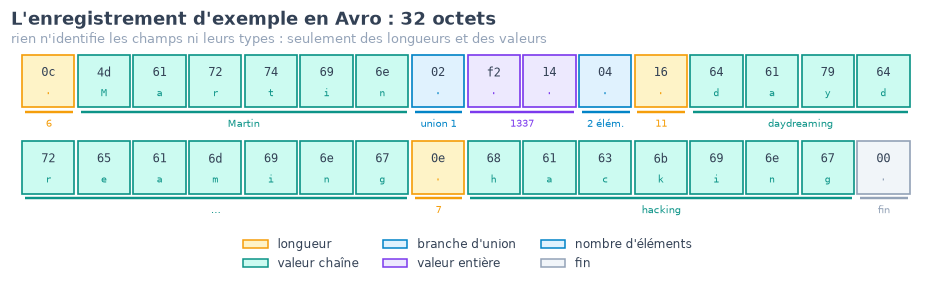

In [3]:
trace = []
av = E.avro_encode(R, W, trace)
fig = E.draw_byte_map(av, trace, title=f"L'enregistrement d'exemple en Avro : {len(av)} octets", per_row=16,
                      subtitle_text="rien n'identifie les champs ni leurs types : seulement des longueurs et des valeurs")
E.byte_legend(fig.axes[0], ["length", "str", "union", "int", "count", "end"], loc="upper center",
              bbox_to_anchor=(0.5, 0.0), ncol=3)
plt.tight_layout(); plt.show()

32 octets, le plus compact de tous. Une chaîne est une longueur (varint zigzag : `0c` =
6) suivie des octets UTF-8 ; l'union commence par l'indice de sa branche (`02` = branche
1, `long`) ; un tableau est une suite de blocs (`04` = 2 éléments, puis `00` = fin).
Mais **rien** ne dit que `0c` est une longueur de chaîne plutôt qu'un entier : pour
décoder, il faut parcourir les champs **dans l'ordre du schéma** et lire chacun selon son
type. Conséquence : il faut exactement le schéma avec lequel la donnée a été écrite.
Essayons de décoder ces 32 octets avec un autre schéma, où l'ordre des champs diffère.

In [4]:
autre_ordre = {"type": "record", "name": "Person", "fields": [W["fields"][1], W["fields"][0], W["fields"][2]]}
try:
    print(E.avro_decode(av, autre_ordre))
except E.AvroError as exc:
    print("échec :", exc)
entiers = {"type": "record", "name": "Person", "fields": [{"name": "a", "type": "long"}, {"name": "b", "type": "long"},
                                                         {"name": "c", "type": "long"}]}
try:
    print("lu comme trois entiers :", E.avro_decode(av[:3], entiers))
except E.AvroError as exc:
    print("échec :", exc)

échec : indice de branche 6 hors de l'union de l'écrivain
lu comme trois entiers : {'a': 6, 'b': -39, 'c': -49}


Avec le mauvais schéma, on obtient au mieux une erreur, au pire des valeurs absurdes
(les trois premiers octets « lus comme des entiers » donnent 6, -39 et -49 : la longueur
de `Martin` puis ses deux premières lettres, décodées en zigzag). Avro tranche ce problème en exigeant que le
lecteur **connaisse le schéma de l'écrivain**.

> **À retenir.** L'encodage Avro n'est qu'une concaténation de valeurs (varints zigzag,
> chaînes préfixées par leur longueur, indices de branche d'union) : 32 octets pour
> l'exemple. Sans le schéma exact de l'écrivain, les octets sont indéchiffrables.

## 2. Schéma de l'écrivain, schéma du lecteur (section *The writer's schema and the reader's schema*)

Une application qui **encode** utilise la version du schéma qu'elle connaît (souvent
compilée dans son code) : c'est le **schéma de l'écrivain**. Une application qui
**décode** utilise deux schémas : celui de l'écrivain (pour savoir comment lire les
octets) et le **sien**, le **schéma du lecteur**, qui décrit les champs et les types que
son code attend. Les deux n'ont pas besoin d'être identiques, seulement **compatibles**.
La bibliothèque Avro **résout** les différences :

- les champs sont appariés **par nom**, l'ordre peut différer ;
- un champ présent chez l'écrivain mais pas chez le lecteur est **ignoré** ;
- un champ attendu par le lecteur mais absent chez l'écrivain prend la **valeur par
  défaut** déclarée dans le schéma du lecteur.

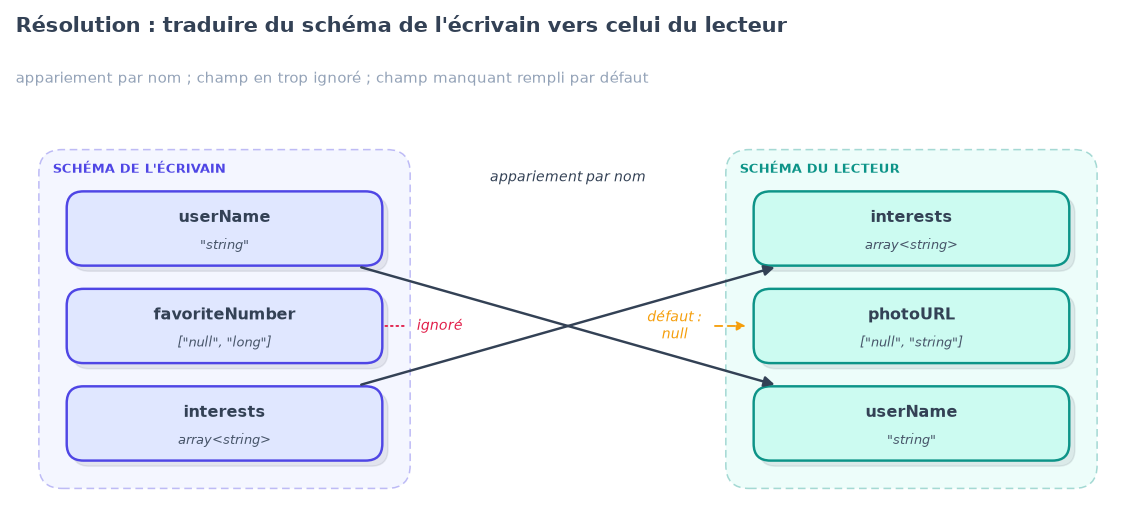

In [5]:
lecteur = {"type": "record", "name": "Person", "fields": [
    {"name": "interests", "type": {"type": "array", "items": "string"}},
    {"name": "photoURL", "type": ["null", "string"], "default": None},
    {"name": "userName", "type": "string"},
]}
d = Diagram(12, 4.4, title="Résolution : traduire du schéma de l'écrivain vers celui du lecteur",
            subtitle="appariement par nom ; champ en trop ignoré ; champ manquant rempli par défaut")
d.group(0.3, 0.2, 4.3, 3.85, "schéma de l'écrivain", color=INDIGO)
d.group(7.7, 0.2, 11.7, 3.85, "schéma du lecteur", color=TEAL)
for i, f in enumerate(W["fields"]):
    d.box(f"w{i}", 2.3, 3.0 - i * 1.05, f["name"], sub=json.dumps(f["type"]) if i < 2 else "array<string>", color=INDIGO, w=3.4, h=0.8)
for i, f in enumerate(lecteur["fields"]):
    d.box(f"r{i}", 9.7, 3.0 - i * 1.05, f["name"], sub="array<string>" if i == 0 else json.dumps(f["type"]), color=TEAL, w=3.4, h=0.8)
d.arrow("w0", "r2", color=SLATE)
d.arrow("w2", "r0", color=SLATE)
d.note(6.0, 3.55, "appariement par nom", color=SLATE)
d.line([(4.0, 1.95), (4.3, 1.95)], color=ROSE, style="dotted", arrow=False)
d.note(4.62, 1.95, "ignoré", color=ROSE)
d.note(7.15, 1.95, "défaut :\nnull", color=AMBER)
d.line([(7.55, 1.95), (7.95, 1.95)], color=AMBER, style="dashed")
d.show()

In [6]:
print("écrit avec l'écrivain :", R)
print("lu par le lecteur     :", E.avro_decode(av, W, lecteur))

écrit avec l'écrivain : {'userName': 'Martin', 'favoriteNumber': 1337, 'interests': ['daydreaming', 'hacking']}
lu par le lecteur     : {'interests': ['daydreaming', 'hacking'], 'photoURL': None, 'userName': 'Martin'}


Le lecteur obtient ses champs dans **son** ordre, `favoriteNumber` a disparu (ignoré),
`photoURL` vaut `None` (défaut). À comparer avec Protocol Buffers (cours 2) : là-bas un
seul schéma suffit au décodage, car chaque champ porte son numéro et son type d'onde ;
ici, l'information est déplacée des données vers le schéma de l'écrivain, qui doit
voyager d'une manière ou d'une autre jusqu'au lecteur (section 4).

> **À retenir.** Avro décode avec deux schémas : celui de l'écrivain, pour lire les
> octets, et celui du lecteur, pour produire ce que le code attend. La résolution
> apparie les champs par nom, ignore les champs en trop et complète les manquants avec
> les valeurs par défaut du lecteur.

## 3. Les règles d'évolution (section *Schema evolution rules*)

Avec Avro, **compatibilité ascendante** signifie qu'un écrivain peut avoir un schéma plus
récent que le lecteur ; **descendante**, que l'écrivain peut avoir un schéma plus ancien.
Les règles découlent directement de la résolution :

- on ne peut ajouter ou supprimer **que des champs qui ont une valeur par défaut**.
  Ajouter un champ sans défaut : un nouveau lecteur ne sait pas quoi mettre dans les
  anciennes données (descendante cassée). Supprimer un champ sans défaut : un ancien
  lecteur l'exige et ne le trouve pas (ascendante cassée) ;
- `null` n'est pas une valeur acceptable pour n'importe quel type : il faut une
  **union** (`["null", "long"]`), et `null` ne peut servir de défaut que s'il est la
  **première** branche. Plus verbeux que « tout est nullable », mais explicite, ce qui
  évite une classe entière de bogues ;
- changer le **type** d'un champ est possible si Avro sait convertir (`int` vers `long`,
  `float` ou `double`, `string` vers `bytes`...) ;
- **renommer** un champ passe par des **alias** dans le schéma du lecteur : compatible
  en descendante (le nouveau lecteur reconnaît l'ancien nom), pas en ascendante ;
- **ajouter une branche à une union** : compatible en descendante seulement.

Le module fournit une vérification statique (`E.avro_compatible(écrivain, lecteur)`), qui
parcourt les deux schémas comme le ferait la résolution. Testons une batterie
d'évolutions de v1 (`Person`), dans les deux sens, et confirmons chaque verdict en
décodant réellement des données.

In [7]:
def v1_avec(*, add=None, drop=None, replace=None):
    """Variante du schéma v1 : ajout d'un champ, suppression, ou remplacement (ancien nom, nouveau champ)."""
    s = copy.deepcopy(W)
    if drop:
        s["fields"] = [f for f in s["fields"] if f["name"] != drop]
    if replace:
        ancien_nom, nouveau = replace
        s["fields"] = [nouveau if f["name"] == ancien_nom else f for f in s["fields"]]
    if add:
        s["fields"].append(add)
    return s

FN = "favoriteNumber"
evolutions = {
    "ajouter un champ avec défaut": v1_avec(add={"name": "photoURL", "type": ["null", "string"], "default": None}),
    "ajouter un champ sans défaut": v1_avec(add={"name": "photoURL", "type": "string"}),
    "supprimer un champ avec défaut": v1_avec(drop=FN),
    "supprimer un champ sans défaut": v1_avec(drop="userName"),
    "renommer (alias chez le lecteur)": v1_avec(replace=("userName", {"name": "name", "aliases": ["userName"], "type": "string"})),
    "long -> double (promotion)": v1_avec(replace=(FN, {"name": FN, "type": ["null", "double"], "default": None})),
    "long -> string": v1_avec(replace=(FN, {"name": FN, "type": ["null", "string"], "default": None})),
    "ajouter une branche d'union": v1_avec(replace=(FN, {"name": FN, "type": ["null", "long", "string"], "default": None})),
}

def adapte(r, writer):
    """L'enregistrement r tel que l'écrirait une application qui utilise le schéma `writer`."""
    out = {}
    for f in writer["fields"]:
        types = f["type"] if isinstance(f["type"], list) else [f["type"]]
        nom = f["name"]
        v = r.get(nom, r["userName"] if nom == "name" else ("p.jpg" if nom == "photoURL" else None))
        if nom == FN and v is not None and "long" not in types:
            v = float(v) if "double" in types else str(v)
        out[nom] = v
    return out

def essai(writer, reader, n=200):
    """Décode réellement n enregistrements écrits avec `writer` en utilisant `reader`."""
    try:
        for r in E.make_people(n, seed=7):
            E.avro_decode(E.avro_encode(adapte(r, writer), writer), writer, reader)
    except E.AvroError:
        return False
    return True

rows = []
for nom, v2 in evolutions.items():
    desc, _ = E.avro_compatible(W, v2)          # écrivain v1, lecteur v2
    asc, _ = E.avro_compatible(v2, W)           # écrivain v2, lecteur v1
    rows.append({"évolution": nom, "descendante (statique)": desc, "descendante (données)": essai(W, v2),
                 "ascendante (statique)": asc, "ascendante (données)": essai(v2, W)})
mat = pd.DataFrame(rows).set_index("évolution")
mat

,descendante (statique),descendante (données),ascendante (statique),ascendante (données)
évolution,,,,
ajouter un champ avec défaut,True,True,True,True
ajouter un champ sans défaut,False,False,True,True
supprimer un champ avec défaut,True,True,True,True
supprimer un champ sans défaut,True,True,False,False
renommer (alias chez le lecteur),True,True,False,False
long -> double (promotion),True,True,False,False
long -> string,False,False,False,False
ajouter une branche d'union,True,True,False,True


Les colonnes « statique » (analyse des schémas) et « données » (décodage réel de 200
enregistrements) concordent, à une exception instructive près : **ajouter une branche
d'union** est déclaré incompatible en ascendante par l'analyse statique, alors que nos
données passent. C'est que notre générateur n'a écrit aucun `favoriteNumber` de type
chaîne : la nouvelle branche n'a jamais servi. Le jour où un écrivain v2 l'utilise, un
lecteur v1 échoue. Tester sur des données ne prouve rien sur les cas absents ; l'analyse
des schémas, si.

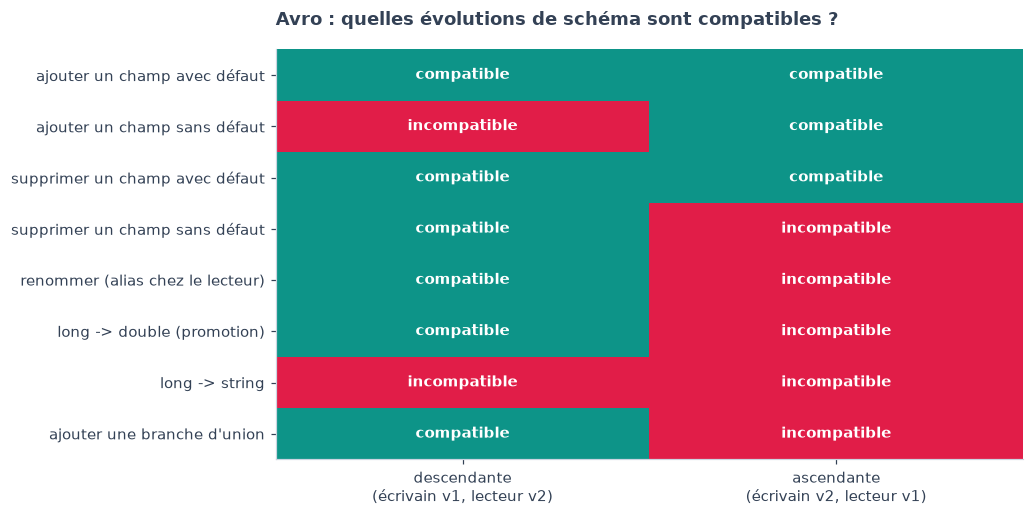

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
vals = mat[["descendante (statique)", "ascendante (statique)"]].values.astype(float)
ax.imshow(vals, cmap="ddia_div", vmin=0, vmax=1, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(2):
        ax.text(j, i, "compatible" if vals[i, j] else "incompatible", ha="center", va="center", color="white",
                fontweight="bold", fontsize=9.5)
ax.set_xticks([0, 1], ["descendante\n(écrivain v1, lecteur v2)", "ascendante\n(écrivain v2, lecteur v1)"])
ax.set_yticks(range(len(mat)), mat.index)
ax.grid(False)
ax.set_title("Avro : quelles évolutions de schéma sont compatibles ?")
plt.tight_layout(); plt.show()

Seuls l'ajout et la suppression de champs **avec défaut** sont compatibles dans les deux
sens (on parle de compatibilité **totale**, « full »). Le renommage, la promotion de type
et l'ajout de branche ne marchent que dans un sens ; `long -> string` dans aucun.

> **À retenir.** En Avro, ajouter ou supprimer un champ n'est compatible dans les deux
> sens que s'il a une valeur par défaut ; `null` passe par une union dont il est la
> première branche ; alias, promotions et nouvelles branches d'union ne sont compatibles
> qu'en descendante.

## 4. Mais quel est le schéma de l'écrivain ? (section *But what is the writer's schema?*)

Le lecteur doit connaître le schéma de l'écrivain. L'inclure dans chaque enregistrement
annulerait le gain : le schéma JSON de `Person` fait plusieurs fois la taille d'un
enregistrement. La réponse dépend du contexte :

1. **un gros fichier de nombreux enregistrements** écrits avec le même schéma (cas
   typique de Hadoop, chapitre 10) : le schéma est écrit **une fois** en tête de
   fichier. C'est le format de **fichier conteneur** (object container file) ;
2. **une base où chaque enregistrement est écrit à son heure**, avec des schémas
   différents : on préfixe chaque enregistrement d'un **numéro de version** et on garde
   la liste des versions dans un **registre de schémas** (c'est ainsi que fonctionnent le
   registre de Confluent pour Kafka et Espresso chez LinkedIn) ;
3. **une connexion réseau bidirectionnelle** : les deux processus négocient la version du
   schéma à l'ouverture et la gardent pour toute la connexion (protocole RPC d'Avro).

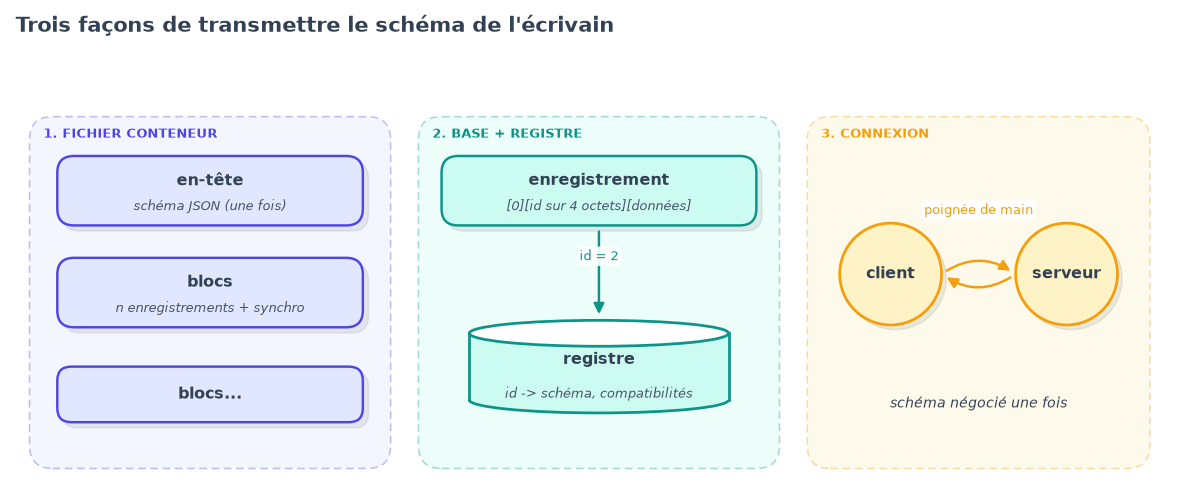

In [9]:
d = Diagram(12.5, 4.6, title="Trois façons de transmettre le schéma de l'écrivain")
d.group(0.2, 0.2, 4.1, 4.0, "1. fichier conteneur", color=INDIGO)
d.box("hdr", 2.15, 3.2, "en-tête", sub="schéma JSON (une fois)", color=INDIGO, w=3.3, h=0.75)
d.box("blk", 2.15, 2.1, "blocs", sub="n enregistrements + synchro", color=INDIGO, w=3.3, h=0.75)
d.box("blk2", 2.15, 1.0, "blocs...", color=INDIGO, w=3.3, h=0.6)
d.group(4.4, 0.2, 8.3, 4.0, "2. base + registre", color=TEAL)
d.box("rec", 6.35, 3.2, "enregistrement", sub="[0][id sur 4 octets][données]", color=TEAL, w=3.4, h=0.75)
d.box("reg", 6.35, 1.3, "registre", sub="id -> schéma, compatibilités", color=TEAL, kind="db", w=2.8, h=1.0)
d.arrow("rec", "reg", "id = 2", color=TEAL)
d.group(8.6, 0.2, 12.3, 4.0, "3. connexion", color=AMBER)
d.box("cli", 9.5, 2.3, "client", color=AMBER, kind="circle", w=1.1)
d.box("srv", 11.4, 2.3, "serveur", color=AMBER, kind="circle", w=1.1)
d.arrow("cli", "srv", "poignée de main", color=AMBER, rad=-0.35, label_offset=(0, 0.55))
d.arrow("srv", "cli", "", color=AMBER, rad=-0.35)
d.note(10.45, 0.9, "schéma négocié une fois", color=SLATE)
d.show()

**Fichier conteneur.** Le module écrit un vrai fichier conteneur simplifié : un en-tête
(octets magiques `Obj\x01`, métadonnées dont le schéma JSON, marqueur de synchronisation
de 16 octets), puis des blocs (nombre d'objets, taille, données, marqueur). Mesurons le
coût par enregistrement de chaque stratégie selon le nombre d'enregistrements.

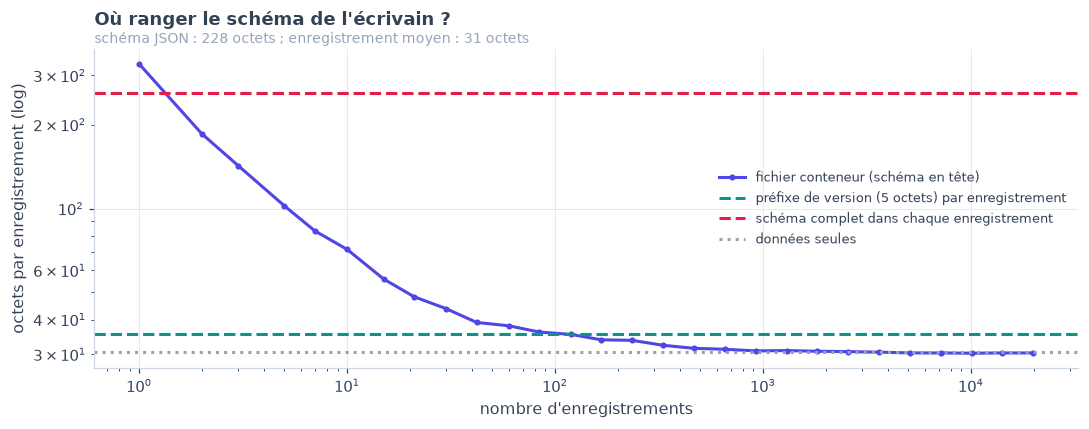

In [10]:
people = E.make_people(20_000, seed=2)
schema_json = len(json.dumps(W).encode())
data_bytes = np.mean([len(E.avro_encode(r, W)) for r in people[:2000]])
ns = np.unique(np.logspace(0, 4.3, 30).astype(int))
cont = [len(E.avro_container_write(people[:n], W, block_size=1000)) / n for n in ns]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ns, cont, color=INDIGO, marker="o", ms=3, label="fichier conteneur (schéma en tête)")
ax.axhline(data_bytes + 5, color=TEAL, ls="--", label="préfixe de version (5 octets) par enregistrement")
ax.axhline(data_bytes + schema_json, color=ROSE, ls="--", label="schéma complet dans chaque enregistrement")
ax.axhline(data_bytes, color=GRAY, ls=":", label="données seules")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nombre d'enregistrements"); ax.set_ylabel("octets par enregistrement (log)")
ax.set_title("Où ranger le schéma de l'écrivain ?")
subtitle(ax, f"schéma JSON : {schema_json} octets ; enregistrement moyen : {data_bytes:.0f} octets")
ax.legend(loc="center right", fontsize=8.5)
plt.tight_layout(); plt.show()

In [11]:
buf = E.avro_container_write(people, W, block_size=1000)
writer_schema, relus = E.avro_container_read(buf, reader=lecteur)
print(f"fichier de {len(people)} enregistrements : {len(buf)} octets ({len(buf) / len(people):.1f} par enregistrement)")
print("schéma trouvé dans l'en-tête :", writer_schema["name"], [f["name"] for f in writer_schema["fields"]])
print("premier enregistrement lu avec le schéma du lecteur :", relus[0])

fichier de 20000 enregistrements : 607068 octets (30.4 par enregistrement)
schéma trouvé dans l'en-tête : Person ['userName', 'favoriteNumber', 'interests']
premier enregistrement lu avec le schéma du lecteur : {'interests': ['bricolage', 'lecture'], 'photoURL': None, 'userName': 'Alice369'}


Inclure le schéma (228 octets) dans chaque enregistrement multiplierait la taille par 8 ou
9. En tête de fichier, son coût disparaît dès quelques centaines d'enregistrements.
Pour des enregistrements écrits un par un, le préfixe de 5 octets (un octet magique et
un identifiant sur 4 octets, le format du registre de Confluent) coûte environ 17 % sur
des enregistrements de cette taille : c'est le prix de l'indépendance de chaque
enregistrement.

**Registre de schémas.** Le registre attribue un identifiant à chaque version et, surtout,
**vérifie la compatibilité** d'une nouvelle version avant de l'accepter, selon un mode
configurable : `BACKWARD` (le nouveau schéma sait lire les données de la version
précédente), `FORWARD` (la version précédente sait lire les données du nouveau), `FULL`
(les deux) ; avec le suffixe `_TRANSITIVE`, la vérification porte sur **toutes** les
versions antérieures, pas seulement la dernière.

In [12]:
reg = E.SchemaRegistry("FULL")
id1 = reg.register("person", W)
v2 = evolutions["ajouter un champ avec défaut"]
id2 = reg.register("person", v2)
print("versions acceptées :", id1, id2)
for nom in ["ajouter un champ sans défaut", "renommer (alias chez le lecteur)"]:
    try:
        reg.register("person", evolutions[nom])
    except E.IncompatibleSchema as exc:
        print(f"refusé ({nom}) : {exc}")
msg_v1 = reg.encode(id1, R)
print(f"message v1 : {msg_v1[:5].hex(' ')} | {len(msg_v1) - 5} octets de données")
print("lu par un consommateur v2 :", reg.decode(msg_v1, reader=v2))

versions acceptées : 1 2
refusé (ajouter un champ sans défaut) : v2 -> nouveau (BACKWARD) : photoURL : null illisible comme string
refusé (renommer (alias chez le lecteur)) : nouveau -> v2 (FORWARD) : champ userName : absent chez l'écrivain et sans défaut chez le lecteur
message v1 : 00 00 00 00 01 | 32 octets de données
lu par un consommateur v2 : {'userName': 'Martin', 'favoriteNumber': 1337, 'interests': ['daydreaming', 'hacking'], 'photoURL': None}


Le registre refuse un champ sans défaut et un renommage, qui casseraient l'une des deux
compatibilités exigées par le mode `FULL`. Un consommateur v2 décode un message v1 : il
lit l'identifiant (`00 00 00 00 01`), récupère le schéma 1 et résout vers son propre
schéma. Un registre de versions est utile même hors Avro : il documente l'historique et
permet de **vérifier la compatibilité avant tout déploiement**.

> **À retenir.** Le schéma de l'écrivain voyage une fois par fichier (fichier conteneur),
> par enregistrement sous forme d'identifiant de version (registre de schémas), ou une fois
> par connexion. Le registre vérifie la compatibilité de chaque nouvelle version.

## 5. Des schémas générés dynamiquement (section *Dynamically generated schemas*)

Pourquoi tenir à l'absence de numéros de champ ? Parce qu'Avro se prête aux schémas
**générés automatiquement**. Exemple du livre : exporter le contenu d'une base
relationnelle dans des fichiers binaires. On génère un schéma Avro par table (une colonne
= un champ, le nom de colonne devient le nom de champ) et on vide la table dans un fichier
conteneur. Si le schéma de la base change, on régénère simplement le schéma à l'export
suivant : les lecteurs apparient les champs **par nom**.

In [13]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE clients (id INTEGER NOT NULL, nom TEXT, ville TEXT, solde REAL)")
con.executemany("INSERT INTO clients VALUES (?, ?, ?, ?)",
                [(i, f"client{i}", ["Lyon", "Paris", "Lille"][i % 3], round(float(rng.normal(500, 200)), 2)) for i in range(5)])

def export(con, table):
    schema = E.avro_schema_from_sqlite(con, table)
    cur = con.execute(f"SELECT * FROM {table}")
    names = [c[0] for c in cur.description]
    return E.avro_container_write([dict(zip(names, row)) for row in cur], schema)

export_lundi = export(con, "clients")
schema_lundi, _ = E.avro_container_read(export_lundi)
# mardi : migration de la base, une colonne ajoutée, une colonne supprimée
con.execute("ALTER TABLE clients ADD COLUMN email TEXT")
con.execute("ALTER TABLE clients DROP COLUMN ville")
con.execute("UPDATE clients SET email = nom || '@exemple.org'")
export_mardi = export(con, "clients")
schema_mardi, _ = E.avro_container_read(export_mardi)
print("schéma de lundi :", [f["name"] for f in schema_lundi["fields"]])
print("schéma de mardi :", [f["name"] for f in schema_mardi["fields"]])
_, lus = E.avro_container_read(export_mardi, reader=schema_lundi)   # un lecteur resté à lundi
pd.DataFrame(lus).head(3)

schéma de lundi : ['id', 'nom', 'ville', 'solde']
schéma de mardi : ['id', 'nom', 'solde', 'email']


,id,nom,ville,solde
0,0,client0,None,525.15
1,1,client1,None,473.58
2,2,client2,None,628.08


Le lecteur « de lundi » lit l'export de mardi sans aucune intervention : `email` est
ignoré, `ville` (nullable, défaut `null`) vaut `None`. L'export n'a rien eu à savoir de
la migration.

Avec des numéros de champ, il faudrait attribuer un numéro à chaque colonne, et ne
**jamais** réattribuer un numéro libéré. Un générateur naïf qui numérote les colonnes
par position commettrait exactement l'erreur du cours 2 :

In [14]:
def pb_schema_par_position(con, table):
    types = {"INTEGER": "int64", "TEXT": "string", "REAL": "double"}
    cols = con.execute(f"PRAGMA table_info({table})").fetchall()
    return PbMessage(table, [PbField(c[1], k + 1, types[c[2]]) for k, c in enumerate(cols)])

con2 = sqlite3.connect(":memory:")
con2.execute("CREATE TABLE clients (id INTEGER, nom TEXT, ville TEXT, solde REAL)")
s_lundi = pb_schema_par_position(con2, "clients")
donnee = E.pb_encode({"id": 1, "nom": "client1", "ville": "Paris", "solde": 812.5}, s_lundi)
con2.execute("ALTER TABLE clients ADD COLUMN email TEXT")
con2.execute("ALTER TABLE clients DROP COLUMN ville")
s_mardi = pb_schema_par_position(con2, "clients")
print("lundi :", [(f.name, f.tag) for f in s_lundi.fields])
print("mardi :", [(f.name, f.tag) for f in s_mardi.fields])
print("donnée de lundi lue avec le schéma de mardi :", E.pb_decode(donnee, s_mardi, keep_unknown=False))

lundi : [('id', 1), ('nom', 2), ('ville', 3), ('solde', 4)]
mardi : [('id', 1), ('nom', 2), ('solde', 3), ('email', 4)]
donnée de lundi lue avec le schéma de mardi : {'id': 1, 'nom': 'client1', 'solde': 0.0, 'email': ''}


Le numéro 3 désignait `ville` lundi et `solde` mardi ; le numéro 4, `solde` puis `email`.
Les types d'onde ne concordent plus : « Paris » (une chaîne) arrive sous le numéro 3, qui
attend un `double`, et 812,5 (un `double`) sous le numéro 4, qui attend une chaîne. Les
deux valeurs sont écartées comme inconnues : le lecteur voit un solde nul et un e-mail
vide. Si les types avaient coïncidé, ce serait pire encore : des valeurs fausses, sans
le moindre signe. Il faudrait un
générateur qui mémorise les numéros déjà attribués : faisable, mais c'est exactement ce
qu'Avro rend inutile. Les schémas dynamiques n'étaient pas un objectif de Protocol
Buffers ; ils l'étaient pour Avro.

**Génération de code et langages dynamiques.** Thrift et Protocol Buffers reposent sur la
génération de code : utile dans un langage à typage statique (Java, C++, C#), où elle
donne des structures efficaces, la vérification des types à la compilation et
l'autocomplétion. Dans un langage dynamique (JavaScript, Ruby, Python), une étape de
compilation n'apporte pas grand-chose et alourdit le travail, surtout avec un schéma
généré dynamiquement. Avro propose la génération de code en option, mais s'en passe très
bien : un fichier conteneur est **autodescriptif** (il contient son schéma), on peut
l'ouvrir avec la bibliothèque Avro et parcourir les enregistrements comme des objets JSON,
exactement ce que fait notre `avro_container_read`. C'est précieux avec des outils
d'analyse dynamiques comme Apache Pig.

> **À retenir.** Sans numéros de champ, un schéma Avro peut être **généré** (par exemple
> depuis le schéma d'une base) et régénéré à chaque changement : l'appariement par nom fait
> le reste. Avec des numéros, il faudrait gérer leur attribution à la main.

## 6. Les mérites des schémas (section *The Merits of Schemas*)

Protocol Buffers, Thrift et Avro ont des langages de schéma bien plus simples que
XML Schema ou JSON Schema (pas de « ce champ doit vérifier telle expression régulière »),
donc faciles à implémenter dans beaucoup de langages. L'idée n'est pas neuve : ASN.1,
normalisé en 1984, utilise déjà des numéros de champ, et son encodage DER sert encore aux
certificats X.509 ; mais il est réputé très complexe. Et la plupart des bases de données
ont leur propre protocole réseau binaire, décodé par un pilote (ODBC, JDBC).

Faisons le bilan des tailles sur 20 000 enregistrements synthétiques, enregistrement par
enregistrement, puis sur le lot entier compressé avec gzip.

In [15]:
pb_recs = [{k: v for k, v in E.to_pb_record(r).items() if v is not None} for r in people]
encoders = {
    "JSON": lambda i: E.json_bytes(people[i]),
    "MessagePack": lambda i: E.msgpack_encode(people[i]),
    "Thrift Compact": lambda i: E.thrift_compact_encode(people[i]),
    "Protocol Buffers": lambda i: E.pb_encode(pb_recs[i], E.PERSON_PB),
    "Avro": lambda i: E.avro_encode(people[i], W),
}
rows = {}
for nom, enc in encoders.items():
    t0 = time.perf_counter()
    blobs = [enc(i) for i in range(len(people))]
    dt = time.perf_counter() - t0
    total = sum(len(b) for b in blobs)
    rows[nom] = {"octets / enreg.": total / len(people),
                 "lot gzip (octets / enreg.)": len(gzip.compress(b"".join(blobs), 6)) / len(people),
                 "encodage Python pur (µs / enreg.)": dt / len(people) * 1e6}
bilan = pd.DataFrame(rows).T
bilan["rapport à JSON"] = bilan["octets / enreg."] / bilan.loc["JSON", "octets / enreg."]
bilan.round(2)

,octets / enreg.,lot gzip (octets / enreg.),encodage Python pur (µs / enreg.),rapport à JSON
JSON,79.32,9.39,1.66,1.00
MessagePack,63.87,10.02,3.14,0.81
Thrift Compact,32.32,8.43,2.64,0.41
Protocol Buffers,32.82,7.91,3.65,0.41
Avro,30.32,8.11,3.46,0.38


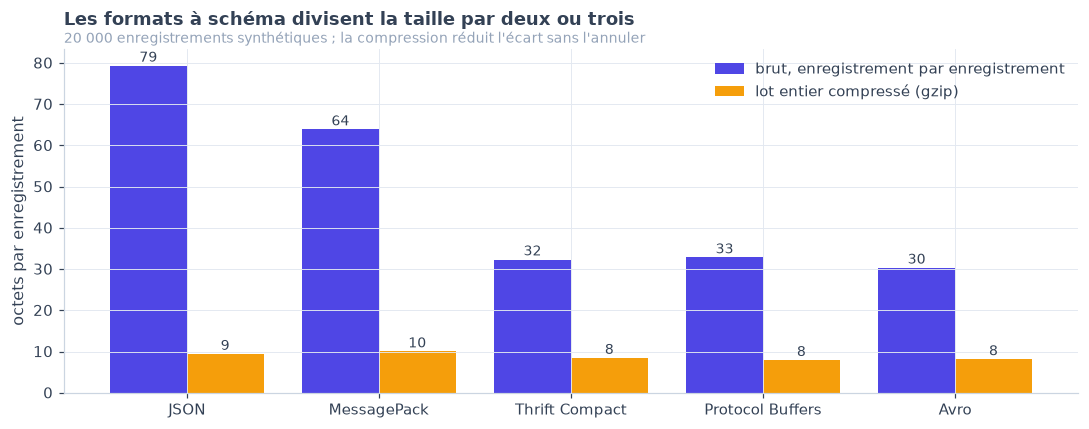

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(bilan))
ax.bar(x - 0.2, bilan["octets / enreg."], 0.4, color=INDIGO, label="brut, enregistrement par enregistrement")
ax.bar(x + 0.2, bilan["lot gzip (octets / enreg.)"], 0.4, color=AMBER, label="lot entier compressé (gzip)")
for i, (a, b) in enumerate(zip(bilan["octets / enreg."], bilan["lot gzip (octets / enreg.)"])):
    ax.text(i - 0.2, a + 1, f"{a:.0f}", ha="center", fontsize=9)
    ax.text(i + 0.2, b + 1, f"{b:.0f}", ha="center", fontsize=9)
ax.set_xticks(x, bilan.index)
ax.set_ylabel("octets par enregistrement")
ax.set_title("Les formats à schéma divisent la taille par deux ou trois")
subtitle(ax, "20 000 enregistrements synthétiques ; la compression réduit l'écart sans l'annuler")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Les formats à schéma (Thrift, Protocol Buffers, Avro) font environ deux à trois fois moins
que JSON. La compression d'un **lot** réduit beaucoup l'écart, car gzip repère les noms de
champs répétés ; mais elle a un coût processeur et ne s'applique pas à un enregistrement
isolé (une ligne de base, un message). Les temps d'encodage mesurés ici sont ceux de nos
encodeurs en Python pur (le JSON bénéficie d'un module écrit en C) : ils ne disent rien
des bibliothèques optimisées, seulement que les formats binaires ne sont pas
intrinsèquement plus chers à produire.

Au-delà de la taille, le livre retient d'autres mérites des schémas binaires :

- le schéma est une **documentation** toujours à jour, puisqu'il est nécessaire au
  décodage ;
- un **registre** de schémas permet de vérifier la compatibilité ascendante et
  descendante **avant** de déployer ;
- dans un langage à typage statique, le **code généré** permet de vérifier les types à
  la compilation.

L'évolution de schéma offre ainsi la même souplesse que les bases « sans schéma »
(schéma à la lecture, chapitre 2), avec de meilleures garanties et de
meilleurs outils. Seul vrai défaut : les données doivent être décodées pour être lues par
un humain.

> **À retenir.** Les formats binaires à schéma sont compacts (32 à 34 octets contre 81),
> documentés par construction, vérifiables avant déploiement et adaptés au code généré.
> Il vaut mieux limiter le nombre de versions de schéma en circulation pour garder
> l'exploitation simple.